In [ ]:
import pandas as pd

In [ ]:
import numpy as np

In [ ]:
df = pd.read_csv("/auto-mpg.csv")

In [ ]:
df

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino
...,...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86,2790,15.6,82,1,ford mustang gl
394,44.0,4,97.0,52,2130,24.6,82,2,vw pickup
395,32.0,4,135.0,84,2295,11.6,82,1,dodge rampage
396,28.0,4,120.0,79,2625,18.6,82,1,ford ranger


In [ ]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [ ]:
df.tail()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
393,27.0,4,140.0,86,2790,15.6,82,1,ford mustang gl
394,44.0,4,97.0,52,2130,24.6,82,2,vw pickup
395,32.0,4,135.0,84,2295,11.6,82,1,dodge rampage
396,28.0,4,120.0,79,2625,18.6,82,1,ford ranger
397,31.0,4,119.0,82,2720,19.4,82,1,chevy s-10


In [ ]:
df.describe()

,mpg,cylinders,displacement,weight,acceleration,model year,origin
count,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,5140.000000,24.800000,82.000000,3.000000


In [ ]:
df.shape

(398, 9)

In [ ]:
df.dtypes


,0
mpg,float64
cylinders,int64
displacement,float64
horsepower,object
weight,int64
acceleration,float64
model year,int64
origin,int64
car name,object


In [ ]:
# Separate numeric and categorical columns
numeric_columns = df.select_dtypes(include=['int64','float64',]).columns.tolist()
catergorical_columns = df.select_dtypes(include=['object']).columns.tolist()

In [ ]:
print(numeric_columns)

['mpg', 'cylinders', 'displacement', 'weight', 'acceleration', 'model year', 'origin']


In [ ]:
print(catergorical_columns)

['horsepower', 'car name']


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# Convert horsepower to numeric, replacing any non-numeric values (like '?') with NaN
df['horsepower'] = pd.to_numeric(df['horsepower'],errors='coerce')
# Fill any missing values in horsepower with the median value
df['horsepower'] = df['horsepower'].fillna(df['horsepower'].median())

# Select numeric colums
X = df[['mpg', 'cylinders', 'displacement', 'horsepower',
        'weight', 'acceleration', 'model year']]

# Rescale data
scaler = MinMaxScaler()
rescaled_data = scaler.fit_transform(X)

#Display result
print(rescaled_data)


[[0.2393617  1.         0.61757106 ... 0.5361497  0.23809524 0.        ]
 [0.15957447 1.         0.72868217 ... 0.58973632 0.20833333 0.        ]
 [0.2393617  1.         0.64599483 ... 0.51686986 0.17857143 0.        ]
 ...
 [0.61170213 0.2        0.17312661 ... 0.19336547 0.21428571 1.        ]
 [0.50531915 0.2        0.13436693 ... 0.2869294  0.63095238 1.        ]
 [0.58510638 0.2        0.13178295 ... 0.31386447 0.67857143 1.        ]]


In [ ]:
from sklearn.preprocessing import LabelEncoder

# Create LabelEncoder object
encoder = LabelEncoder()

# Encoder categorical column
df['car name'] = encoder.fit_transform(df['car name'])

#display encoder data
print(df[['car name']].head())

   car name
0        49
1        36
2       231
3        14
4       161


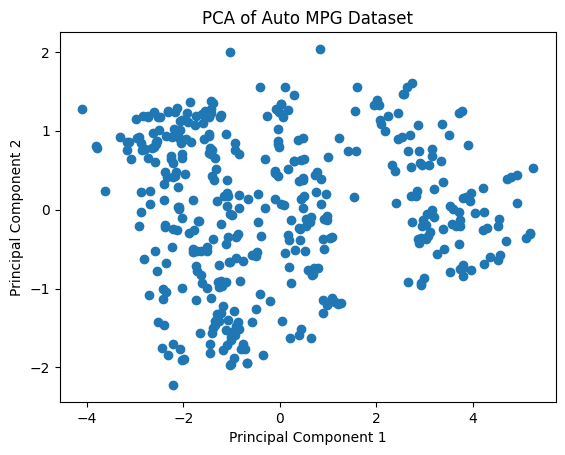

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


# Select numeric features
X = df[['mpg', 'cylinders', 'displacement', 'horsepower',
        'weight', 'acceleration', 'model year']]

# Handle missing values
X = X.fillna(X.mean())

# Standardize data
X_scaled = StandardScaler().fit_transform(X)

#Apply PCA
pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_scaled)

# Plot
plt.scatter(principal_components[:, 0], principal_components[:, 1])
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Auto MPG Dataset")
plt.show()

